# Recalibración de la capa histórica de CO₂ · v2

Comparación de tres fuentes: histórica combinada, qN y q0. **Química theta_nv2 fija.** Cada caso obtiene su propio ajuste de kCO2_release_h, CO2sat_scale y matrix_gain, compartido entre LAB019–021. LAB016–018 es holdout sin reajuste. No se calibran parámetros químicos, O₂, activación ni respuesta nutricional A, tau_r, tau_d, pulse_activity_gain o duración de rampa.

**v2 del diagnóstico 06: factor de actividad conservado.** Fuentes únicas: B=a(t)qN y B=a(t)q0.

Se conservan las trayectorias auxiliares, activación, O₂ y Csat de la referencia histórica; es una comparación de fuentes, no la eliminación de toda segunda trayectoria en el modelo completo.

## Política del ajuste

- Medianas horarias RAW convertidas por volumen remanente; predicciones físicas sin filtrado añadido.
- Mismo soporte temporal del lector histórico: cubrir las mediciones offline y política de caudal bajo, con umbral de detección 0.05 y nivel final 0.02 g/(L·h), ventana de 2 h. Se imprimen los cortes por LAB. A diferencia de v1, las tablas v2 usan este soporte común recortado; no comparar directamente errores v1/v2 sin atender al soporte.
- Objetivo: suma de errores cuadrados medios por LAB019–021. Para observación inferior a 0.05, residuo max(predicción−0.05,0); para las demás, predicción−observación. Igual peso por laboratorio. El tratamiento censurado se aplica ahora al objetivo; en v1 era sólo una métrica adicional porque no se calibraba.
- Tres arranques por caso, parámetros positivos en logaritmos, límites históricos: liberación 0.03–25 h⁻¹; escala Csat 0.35–2.5; ganancia 0.1–20. No se amplían límites para mejorar resultados.
- Se evalúan el resultado congelado y el recalibrado sobre exactamente las mismas observaciones. Se muestran convergencia, objetivos de los tres arranques, límites y sensibilidad del Jacobiano.
- No se guardan nuevos parámetros fuera del EXECUTED ni se sobrescriben ajustes existentes. Sin CSV/PNG externos.

## Expresiones

r es la rampa histórica y a(t)=1+(gN−1)r, con gN=0.25. Se conserva $q_{prod}=gate\ f_{O2}\ M\ B$ y la transferencia histórica $q_{gas}=k C_d[0.05+0.95C_d/(C_d+C_{sat})]$, $\dot C_d=q_{prod}-q_{gas}$, salida $gq_{gas}$.

La fuente histórica usa $B=\max[a q_0+r(q_N-q_0),0]$. Las dos alternativas se definen a continuación y no se intercambian entre las versiones 05/06. El transitorio M sigue activo también en el caso q0: no representa una fermentación totalmente sin efectos nutricionales.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load,release_forward,GAS_NAMES
from wine_fermentation.comparison import observations
protected=[p for folder in ('src','configs','notebooks','results') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and p.name not in ['05_historical_single_trajectory_v2.source.ipynb', '05_historical_single_trajectory_v2.executed.ipynb', '06_historical_single_trajectory_fixed_activity_v2.source.ipynb', '06_historical_single_trajectory_fixed_activity_v2.executed.ipynb']]
def hashes():return {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
before=hashes()
v=load(ROOT)
v.prepare('theta_nv2',v.thetas['theta_nv2'],tuple(f'LAB{i:03}' for i in range(16,22)))
stored=json.loads((ROOT/'configs/models/historical/gas_fit.json').read_text())['experiments']['train_019_021']
p={k:stored[k] for k in GAS_NAMES}
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
observed=observations(raw)
display(pd.Series(p,name='Coeficientes fijos'))
display(pd.Series({k:v.old[k] for k in ['pulse_activity_gain','pulse_t_rise_h','A','tau_rise_h','tau_decay_h','N_ref_g_l','O2_initial_scale','O2_qmax_mg_gdw_h']}))

KEEP_ACTIVITY=True


kCO2_release_h    1.229635
CO2sat_scale      2.500000
matrix_gain       0.836671
Name: Coeficientes fijos, dtype: float64

pulse_activity_gain     0.250000
pulse_t_rise_h         64.658704
A                       0.300000
tau_rise_h              4.000000
tau_decay_h            12.000000
N_ref_g_l               0.140000
O2_initial_scale        0.195400
O2_qmax_mg_gdw_h        0.150000
dtype: float64

In [2]:
from scipy.optimize import least_squares
from wine_fermentation.models.historical.calibration import GAS_BOUNDS
TRAIN=LABS[:3];HOLDOUT=LABS[3:]
CASES=['Histórica','Sólo con nutrición','Sólo sin nutrición']
lo,hi=np.asarray(GAS_BOUNDS,float).T
support={}
for lab in LABS:
 c=v.cache['theta_nv2',lab]
 o=observed[lab]
 support[lab]=o[o.time_h.between(c['time'][0],min(c['time'][-1],v.horizons[lab]))].copy()
 assert len(support[lab])>0
sources={}
for lab in LABS:
 c=v.cache['theta_nv2',lab];ramp=c['ramp'];activity=1+(v.old['pulse_activity_gain']-1)*ramp
 brackets={'Histórica':np.maximum(activity*c['q0']+ramp*(c['qn']-c['q0']),0),
           'Sólo con nutrición':(activity if KEEP_ACTIVITY else 1.)*c['qn'],
           'Sólo sin nutrición':(activity if KEEP_ACTIVITY else 1.)*c['q0']}
 for name,B in brackets.items():
  source=c['gate']*c['fferm']*c['multiplier']*B
  if name=='Histórica':
   assert np.allclose(source,c['source'],atol=1e-12,rtol=1e-12)
   source=c['source'].copy()
  sources[name,lab]={**c,'source':source}
 # Before nutrition the sources coincide, independent of future fitted gas parameters.
 prior=c['time']<c['events'][0][0]
 for name in CASES:
  assert np.max(abs(sources[name,lab]['source'][prior]-c['source'][prior]))<1e-5

def prediction(name,lab,values):
 return release_forward(sources[name,lab],dict(zip(GAS_NAMES,values)))

def objective(logvalues,name):
 values=np.exp(logvalues);parts=[]
 for lab in TRAIN:  # Holdout is never accessed in the optimizer.
  o=support[lab];pred=prediction(name,lab,values)[0];t=sources[name,lab]['time']
  y=o.co2_raw_g_l_h.to_numpy();yp=np.interp(o.time_h,t,pred)
  error=np.where(y<.05,np.maximum(yp-.05,0.),yp-y)
  parts.append(error/np.sqrt(len(error)))
 return np.concatenate(parts)

fit_values={};fits=[];start_values=np.array([p[k] for k in GAS_NAMES])
for name in CASES:
 runs=[]
 for start in (start_values,np.array([.4,1.,.7]),np.array([2.,1.,1.])):
  sol=least_squares(lambda x:objective(x,name),np.log(np.clip(start,lo+1e-8,hi-1e-8)),
   bounds=(np.log(lo),np.log(hi)),max_nfev=100,ftol=1e-7,xtol=1e-7,gtol=1e-7)
  runs.append(sol)
 best=min(runs,key=lambda s:float(s.fun@s.fun));values=np.exp(best.x);fit_values[name]=values
 frozen=objective(np.log(start_values),name)
 singular=np.linalg.svd(best.jac,compute_uv=False)
 fits.append(dict(case=name,**dict(zip(GAS_NAMES,map(float,values))),success=bool(best.success),message=best.message,
  frozen_objective=float(frozen@frozen),fitted_objective=float(best.fun@best.fun),nfev=best.nfev,
  active_bounds=','.join(k for k,a in zip(GAS_NAMES,best.active_mask) if a),
  jacobian_ratio=float(singular[-1]/singular[0]) if singular[0] else 0.,
  multistart_objectives=[float(s.fun@s.fun) for s in runs],training_labs=list(TRAIN),holdout_labs=list(HOLDOUT)))
 print(name,'objective',fits[-1]['fitted_objective'],'converged',best.success,flush=True)
display(pd.DataFrame(fits))
display(pd.DataFrame({'parameter':GAS_NAMES,'lower':lo,'upper':hi}))
display(pd.DataFrame([dict(lab=lab,cut_h=float(v.horizons[lab]),last_offline_h=float(next(x for x in v.coverage_rows if x['lab']==lab)['last_chemical_or_offline_h']),n=len(support[lab])) for lab in LABS]))

curves={};rows=[]
for name in CASES:
 for lab in LABS:
  c=sources[name,lab];t=c['time'];source=c['source']
  for stage,values in [('Congelado',start_values),('Recalibrado',fit_values[name])]:
   pred,cd,qgas=prediction(name,lab,values)
   assert np.max(abs(np.diff(cd)-np.diff(t)*(source[:-1]-qgas[1:])))<1e-9
   assert cd.min()>=0 and qgas.min()>-1e-10
   if stage=='Recalibrado':curves[name,lab]=pd.DataFrame(dict(qprod=source,qpred=pred,Cd=cd,qgas=qgas),index=t)
   o=support[lab];yp=np.interp(o.time_h,t,pred);y=o.co2_raw_g_l_h.to_numpy();error=yp-y
   censored=np.where(y<.05,np.maximum(yp-.05,0),error)
   rows.append(dict(lab=lab,case=name,stage=stage,role='Calibración' if lab in TRAIN else 'Holdout',n=len(error),
    RMSE=np.sqrt(np.mean(error**2)),bias=error.mean(),censored_RMSE=np.sqrt(np.mean(censored**2)),
    area_pred_g_L=np.trapz(yp,o.time_h),area_observed_g_L=np.trapz(y,o.time_h),peak=float(pred.max()),peak_h=float(t[pred.argmax()])))
metrics_all=pd.DataFrame(rows);metrics=metrics_all[metrics_all.stage.eq('Recalibrado')]
display(metrics_all.round(5))
display(metrics_all.groupby(['stage','role','case'])[['RMSE','censored_RMSE','bias','area_pred_g_L']].mean().round(5))


Histórica objective 0.06427100068062797 converged True


Sólo con nutrición objective 0.05872073170908311 converged True


Sólo sin nutrición objective 0.05937733665827477 converged True


,case,kCO2_release_h,CO2sat_scale,matrix_gain,success,message,frozen_objective,fitted_objective,nfev,active_bounds,jacobian_ratio,multistart_objectives,training_labs,holdout_labs
0,Histórica,1.217553,2.500000,0.837994,True,`ftol` termination condition is satisfied.,0.064272,0.064271,7,CO2sat_scale,0.002690,"[0.06427100103311803, 0.06427100068062797, 0.0...","[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]"
1,Sólo con nutrición,6.319859,1.940315,0.778529,True,`ftol` termination condition is satisfied.,0.061058,0.058721,15,,0.000817,"[0.05872073207861367, 0.05872073170908311, 0.0...","[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]"
2,Sólo sin nutrición,1.118489,2.500000,0.880109,True,`gtol` termination condition is satisfied.,0.060125,0.059377,8,CO2sat_scale,0.002977,"[0.05937733666554158, 0.05937733665827477, 0.0...","[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]"


,parameter,lower,upper
0,kCO2_release_h,0.03,25.0
1,CO2sat_scale,0.35,2.5
2,matrix_gain,0.10,20.0


,lab,cut_h,last_offline_h,n
0,LAB019,166.000000,166.000000,166
1,LAB020,172.333333,166.000000,172
2,LAB021,166.000000,166.000000,166
3,LAB016,151.100000,56.184722,152
4,LAB017,141.000000,56.183333,141
5,LAB018,141.000000,56.181389,141


,lab,case,stage,role,n,RMSE,bias,censored_RMSE,area_pred_g_L,area_observed_g_L,peak,peak_h
0,LAB019,Histórica,Congelado,Calibración,166,0.14841,0.01969,0.14800,43.23214,39.94782,0.63857,70.33333
1,LAB019,Histórica,Recalibrado,Calibración,166,0.14851,0.02010,0.14810,43.30013,39.94782,0.63952,70.33333
2,LAB020,Histórica,Congelado,Calibración,172,0.05118,-0.00009,0.05053,36.12433,36.13323,0.56491,78.08333
3,LAB020,Histórica,Recalibrado,Calibración,172,0.05117,0.00024,0.05051,36.18099,36.13323,0.56575,78.08333
4,LAB021,Histórica,Congelado,Calibración,166,0.20079,-0.03621,0.19954,34.16194,40.16883,0.65200,53.83333
5,LAB021,Histórica,Recalibrado,Calibración,166,0.20073,-0.03589,0.19947,34.21575,40.16883,0.65294,53.83333
6,LAB016,Histórica,Congelado,Holdout,152,0.14268,0.02008,0.14155,49.28954,46.20458,0.77281,63.16667
7,LAB016,Histórica,Recalibrado,Holdout,152,0.14285,0.02059,0.14173,49.36703,46.20458,0.77391,63.16667
8,LAB017,Histórica,Congelado,Holdout,141,0.11404,0.00635,0.11323,52.07466,51.17498,0.94434,63.66667
9,LAB017,Histórica,Recalibrado,Holdout,141,0.11410,0.00694,0.11330,52.15647,51.17498,0.94561,63.66667


RMSE  censored_RMSE     bias  \
stage       role        case                                                  
Congelado   Calibración Histórica           0.13346        0.13269 -0.00554   
                        Sólo con nutrición  0.13275        0.13106  0.01744   
                        Sólo sin nutrición  0.13134        0.12862 -0.00220   
            Holdout     Histórica           0.12281        0.12193  0.01159   
                        Sólo con nutrición  0.16678        0.16626  0.05072   
                        Sólo sin nutrición  0.10978        0.10903  0.01599   
Recalibrado Calibración Histórica           0.13347        0.13269 -0.00518   
                        Sólo con nutrición  0.12979        0.12836  0.00079   
                        Sólo sin nutrición  0.13126        0.12822  0.00958   
            Holdout     Histórica           0.12290        0.12203  0.01213   
                        Sólo con nutrición  0.15701        0.15614  0.02436   
                        Sólo sin nutrición  0.11530        0.11456  0.03413   

                                            area_pred_g_L  
stage       role        case                               
Congelado   Calibración Histórica                37.83947  
                        Sólo con nutrición       41.69254  
                        Sólo sin nutrición       38.38493  
            Holdout     Histórica                50.18433  
                        Sólo con nutrición       55.81619  
                        Sólo sin nutrición       50.80797  
Recalibrado Calibración Histórica                37.89895  
                        Sólo con nutrición       38.89982  
                        Sólo sin nutrición       40.36087  
            Holdout     Histórica                50.26311  
                        Sólo con nutrición       52.01174  
                        Sólo sin nutrición       53.42776

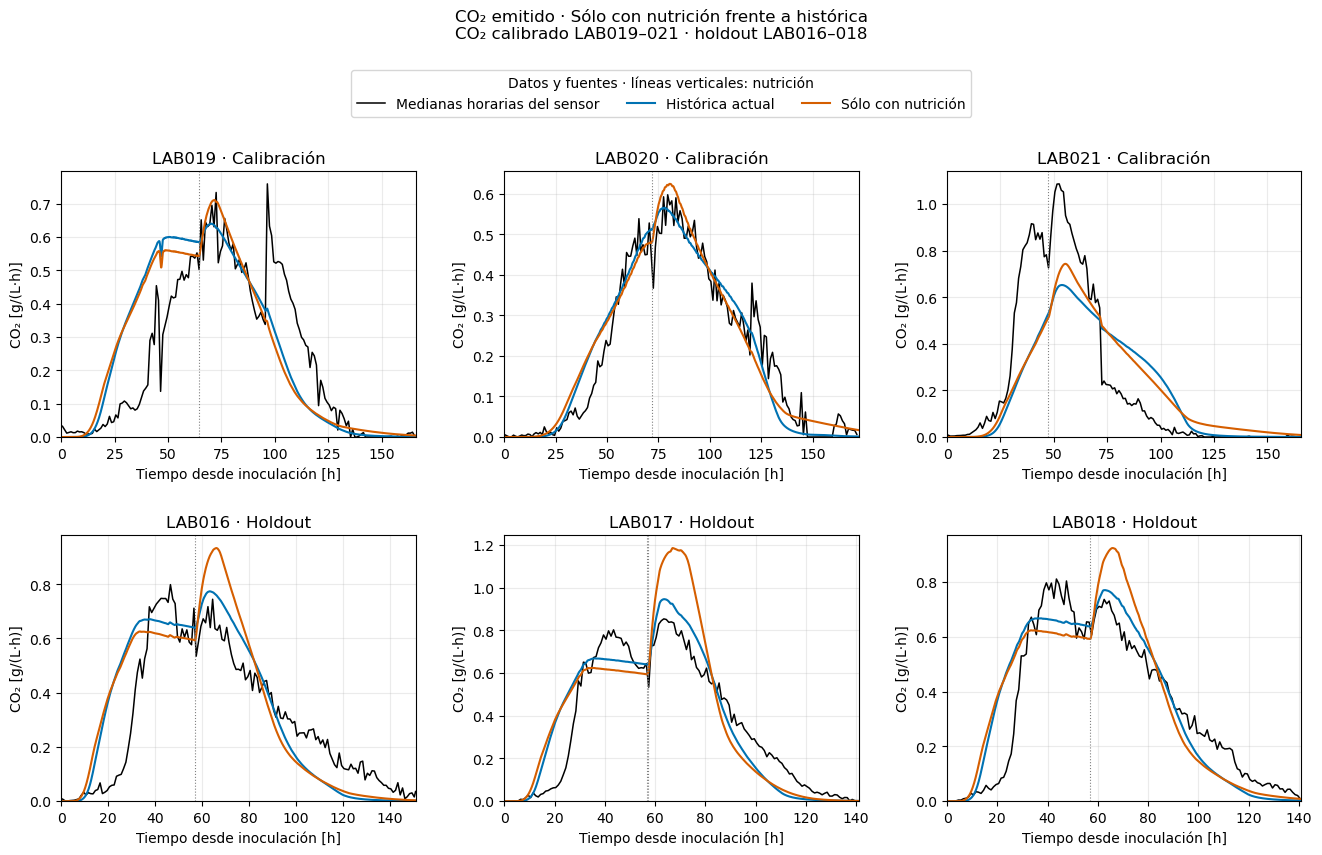

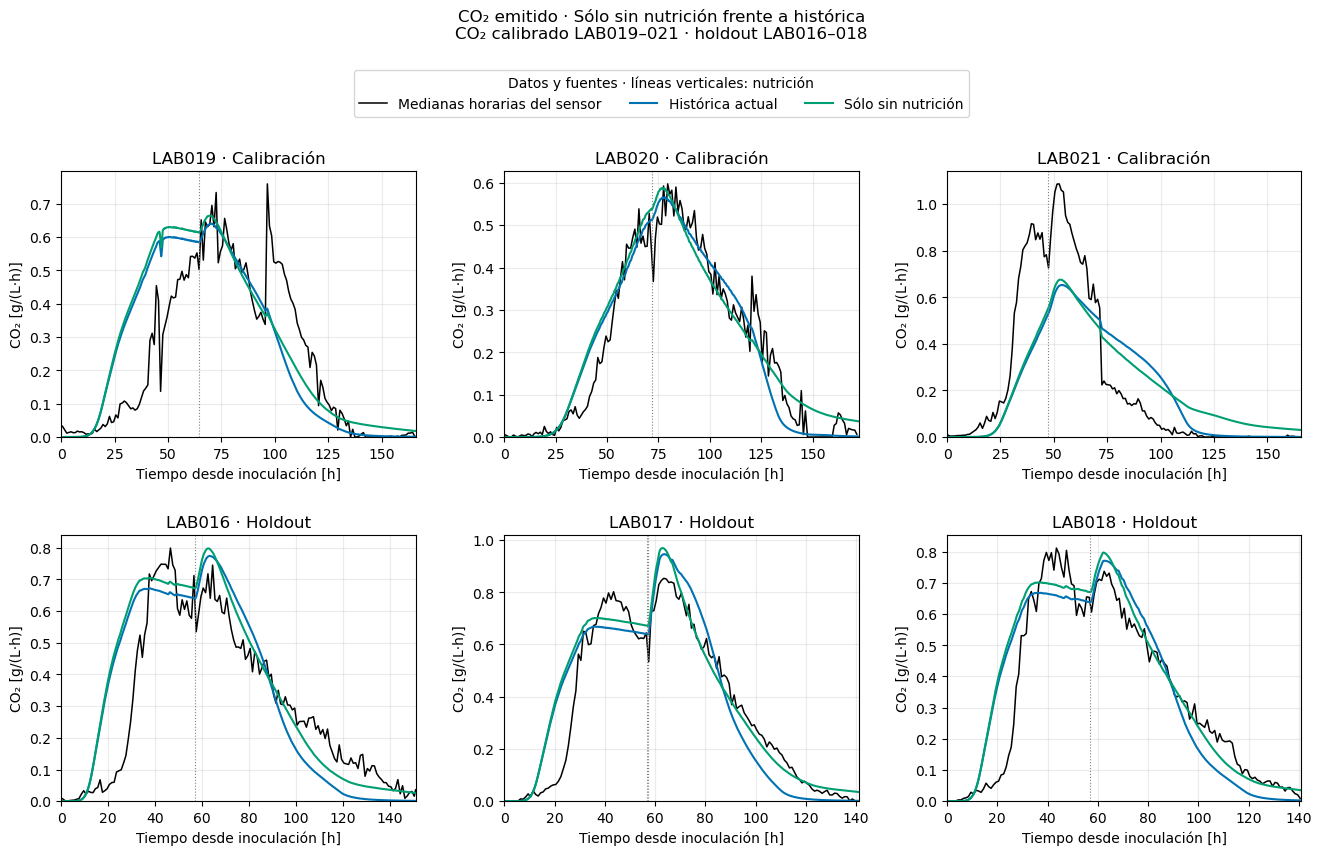

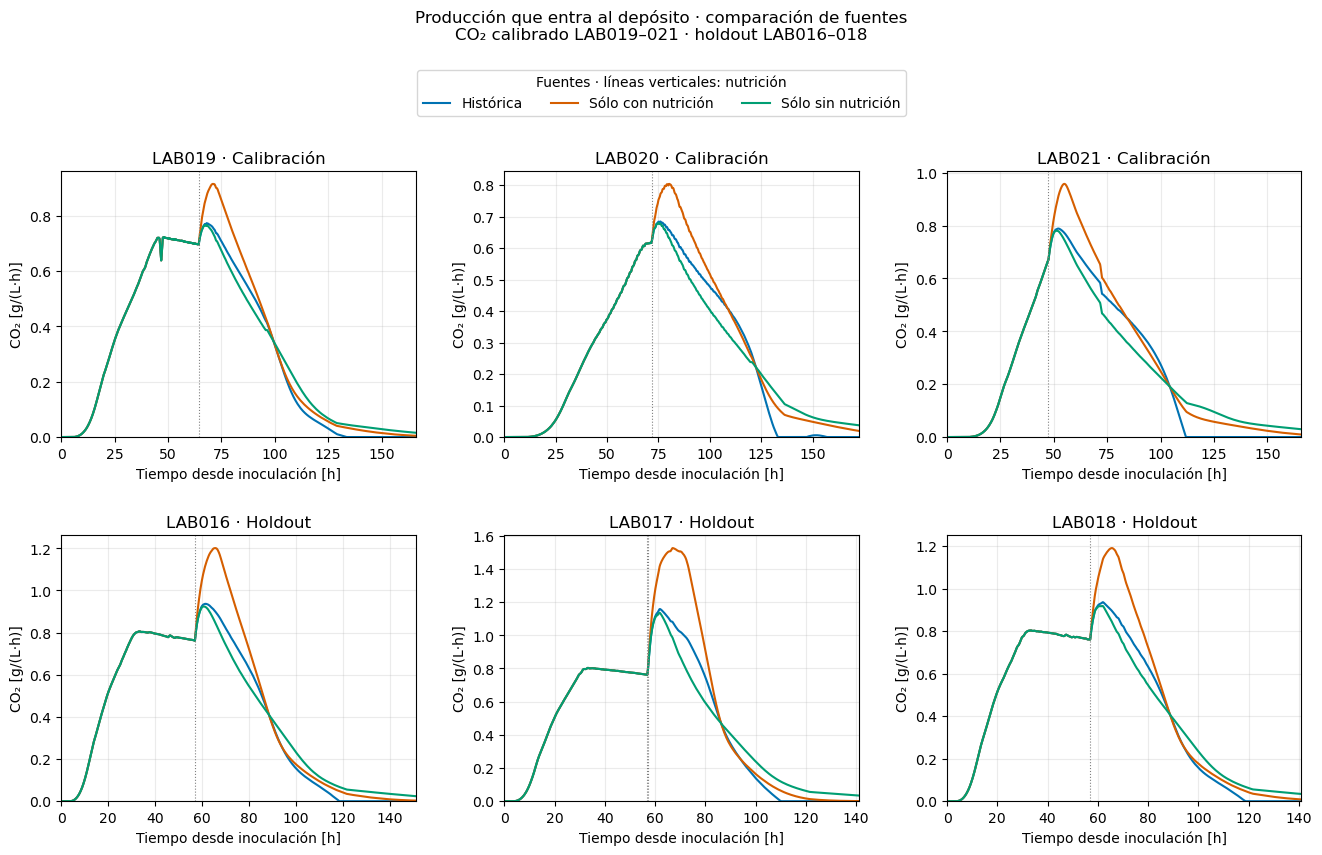

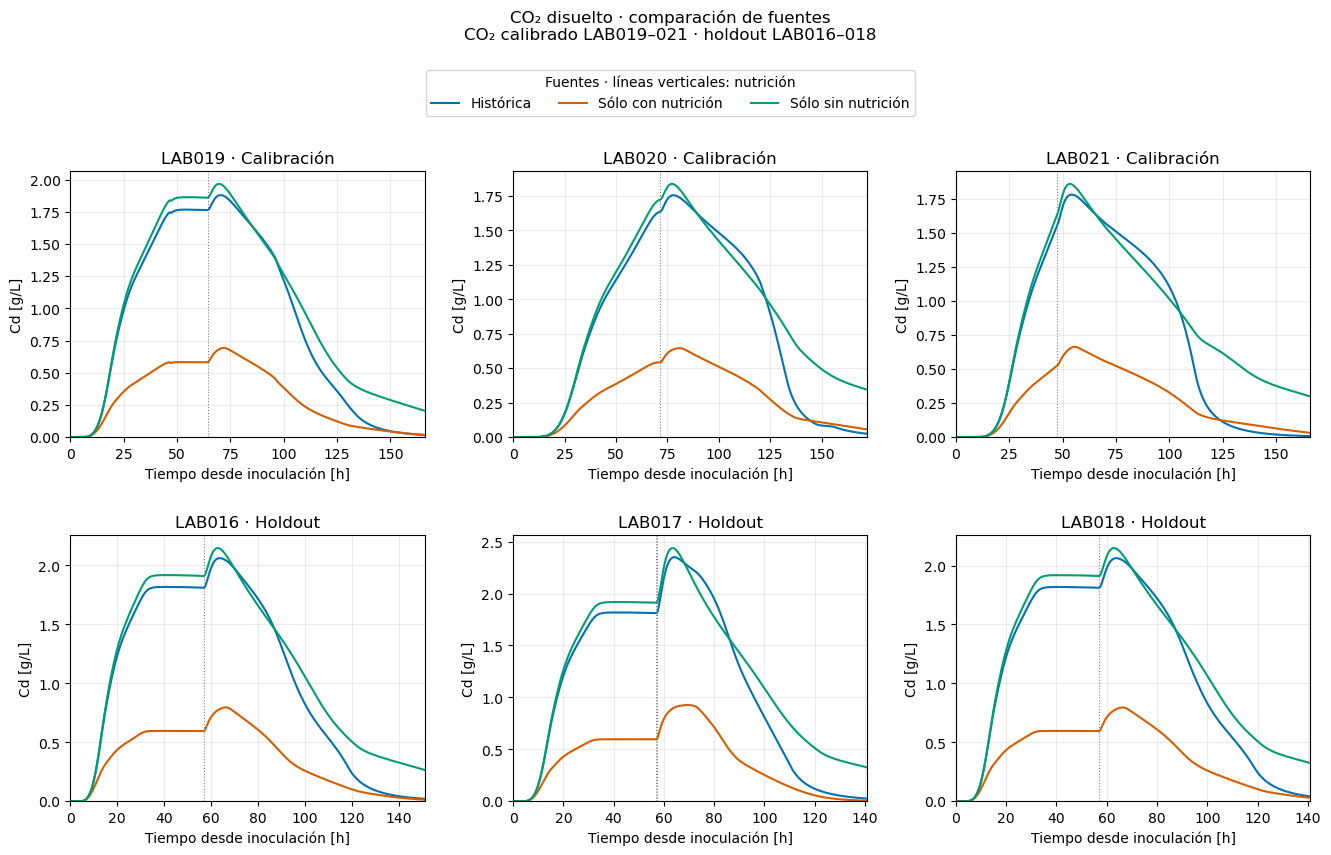

RMSE     bias  area_pred_g_L
role        case                                               
Calibración Histórica           0.13347 -0.00518       37.89895
            Sólo con nutrición  0.12979  0.00079       38.89982
            Sólo sin nutrición  0.13126  0.00958       40.36087
Holdout     Histórica           0.12290  0.01213       50.26311
            Sólo con nutrición  0.15701  0.02436       52.01174
            Sólo sin nutrición  0.11530  0.03413       53.42776

Verificado: modelos, parámetros, resultados previos y notebooks anteriores intactos. Sin exportar CSV/PNG.


In [3]:
def panels(title):
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 fig.suptitle(title+'\nCO₂ calibrado LAB019–021 · holdout LAB016–018',y=.99)
 fig.subplots_adjust(top=.81,hspace=.37,wspace=.25)
 return fig,axes
for alternative,color in [('Sólo con nutrición','#D55E00'),('Sólo sin nutrición','#009E73')]:
 fig,axes=panels('CO₂ emitido · '+alternative+' frente a histórica')
 for ax,lab in zip(axes.flat,LABS):
  o=support[lab];old=curves['Histórica',lab].loc[:v.horizons[lab]];alt=curves[alternative,lab].loc[:v.horizons[lab]]
  ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
  ax.plot(old.index,old.qpred,color='#0072B2',label='Histórica actual')
  ax.plot(alt.index,alt.qpred,color=color,label=alternative)
  for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
  role='Calibración' if lab in LABS[:3] else 'Holdout'
  ax.set(title=lab+' · '+role,xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(0,old.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.93),ncol=3,title='Datos y fuentes · líneas verticales: nutrición')
 plt.show()
for variable,title,ylabel in [('qprod','Producción que entra al depósito','CO₂ [g/(L·h)]'),('Cd','CO₂ disuelto','Cd [g/L]')]:
 fig,axes=panels(title+' · comparación de fuentes')
 for ax,lab in zip(axes.flat,LABS):
  for name,color in [('Histórica','#0072B2'),('Sólo con nutrición','#D55E00'),('Sólo sin nutrición','#009E73')]:
   f=curves[name,lab].loc[:v.horizons[lab]];ax.plot(f.index,f[variable],label=name,color=color)
  for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
  role='Calibración' if lab in LABS[:3] else 'Holdout'
  ax.set(title=lab+' · '+role,xlabel='Tiempo desde inoculación [h]',ylabel=ylabel,xlim=(0,f.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.93),ncol=3,title='Fuentes · líneas verticales: nutrición')
 plt.show()
display(metrics.groupby(['role','case'])[['RMSE','bias','area_pred_g_L']].mean().round(5))
assert hashes()==before,'Se modificó un archivo protegido'
print('Verificado: modelos, parámetros, resultados previos y notebooks anteriores intactos. Sin exportar CSV/PNG.')


## Resultados v2 con actividad conservada

Los nueve arranques terminaron con convergencia. Química y respuesta nutricional fijas; sólo liberación, escala de saturación y ganancia reajustadas.

| Caso | Liberación [h⁻¹] | Escala Csat | Ganancia | RMSE medio calibración | RMSE medio holdout |
|---|---:|---:|---:|---:|---:|
| Histórica | 1.217553 | 2.500000 | 0.837994 | 0.13347 | 0.12290 |
| qN con a(t) | 6.319859 | 1.940315 | 0.778529 | 0.12979 | 0.15701 |
| q0 con a(t) | 1.118489 | 2.500000 | 0.880109 | 0.13126 | 0.11530 |

Los RMSE están en g/(L·h). El objetivo optimizado es censurado y suma cuadrados medios; no es la media de RMSE ordinarios mostrada en esta tabla. La histórica y q0 llegan al máximo de escala de saturación. Ningún caso utiliza información del holdout para seleccionar parámetros.

q0 reajustado conserva menor RMSE medio de holdout que la histórica reajustada, pero su propio resultado congelado era mejor: 0.10978 frente a 0.11530 en el mismo soporte. Por tanto, mejorar el objetivo de calibración no garantiza mejorar el holdout. qN mejora el objetivo de calibración, pero sigue peor en holdout.

Las fuentes coinciden antes de nutrir; las curvas emitidas pueden diferir antes de nutrir por sus parámetros de transferencia distintos. Se conserva exactamente el factor de actividad en las alternativas y todos los factores auxiliares históricos. Esto no elimina aún las dependencias auxiliares de la segunda trayectoria.

El soporte y el objetivo v2 están especificados arriba. Los resultados v1 no deben compararse directamente porque utilizaban toda la cobertura disponible y no realizaban ajuste censurado.


## Química · Histórica actual frente a Sólo sin nutrición

Se mantienen las identidades y colores de la comparación de CO₂: **Histórica actual, azul; Sólo sin nutrición, verde**. En esta última etiqueta, «sin nutrición» identifica exclusivamente la fuente q0 del gas, no la eliminación de pulsos de la predicción química.

**Ambos casos conservan exactamente la misma química theta_nv2 con los pulsos registrados.** La fuente de CO₂ y su recalibración no realimentan los balances químicos. Por ello las curvas se superponen y la tabla de diferencias es cero. La línea verde discontinua permite ver la superposición con la azul. Las anteriores figuras de química con/sin pulsos eran un contrafactual distinto y se sustituyen aquí para mantener la comparación solicitada. No se recalibra nada.

La fuente histórica combina max[a q0+r(qN-q0),0], antes de los factores comunes. Sólo sin nutrición usa q0 en 05 y a q0 en 06, antes de esos factores. **La química histórica no es la suma de dos trayectorias químicas.** q0 y qN son fuentes calculadas a partir de simulaciones auxiliares; la salida química de estos ensayos sigue siendo la trayectoria con los pulsos reales.

Se conservan todas las muestras numéricas disponibles de LAB019–021, incluidas iniciales y NUT de YAN. Para LAB016–018 se muestra biomasa viable experimental y G+F estimado con la relación histórica S=2.5*(densidad_g_L-1000). La densidad no se reparte entre glucosa y fructosa. Se identifican los paneles sin mediciones y se enumeran las muestras dibujadas. Las etiquetas calibración/holdout corresponden a la capa de CO₂, no a un nuevo ajuste químico.


,LAB,variable,unidad,max_diferencia_absoluta,hora_max_diferencia,diferencia_final,final_historica,final_solo_sin_nutricion,fin_h
0,LAB019,Etanol,g/L,0.0,0.0,0.0,84.88840,84.88840,183.08194
1,LAB019,Glucosa,g/L,0.0,0.0,0.0,0.00000,0.00000,183.08194
2,LAB019,Fructosa,g/L,0.0,0.0,0.0,0.16440,0.16440,183.08194
3,LAB019,Glucosa + fructosa,g/L,0.0,0.0,0.0,0.16440,0.16440,183.08194
4,LAB019,Biomasa viable,g/L,0.0,0.0,0.0,1.74690,1.74690,183.08194
5,LAB019,YAN,mg/L,0.0,0.0,0.0,0.00000,0.00000,183.08194
6,LAB020,Etanol,g/L,0.0,0.0,0.0,84.10377,84.10377,183.08194
7,LAB020,Glucosa,g/L,0.0,0.0,0.0,0.00000,0.00000,183.08194
8,LAB020,Fructosa,g/L,0.0,0.0,0.0,1.55441,1.55441,183.08194
9,LAB020,Glucosa + fructosa,g/L,0.0,0.0,0.0,1.55441,1.55441,183.08194


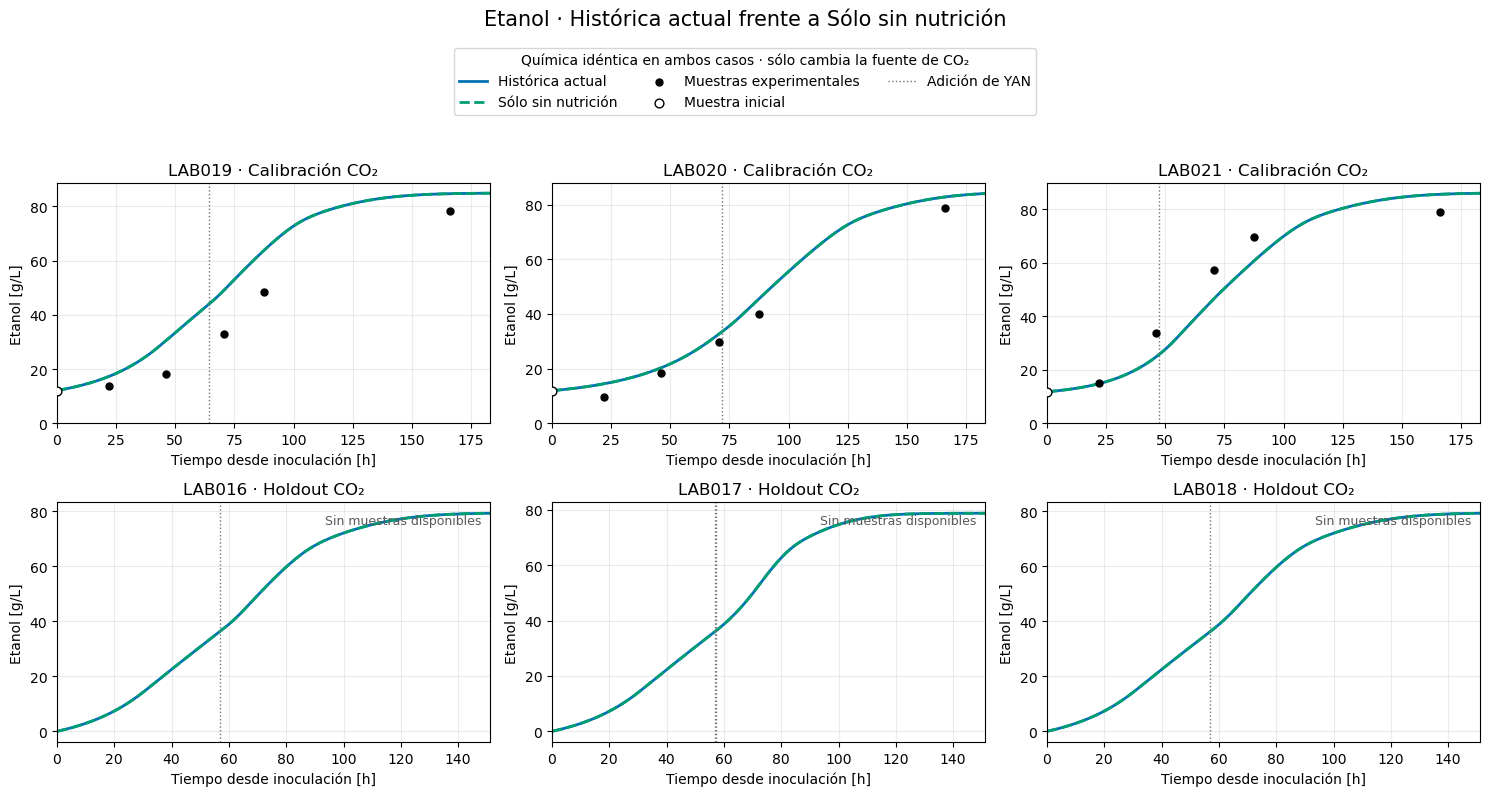

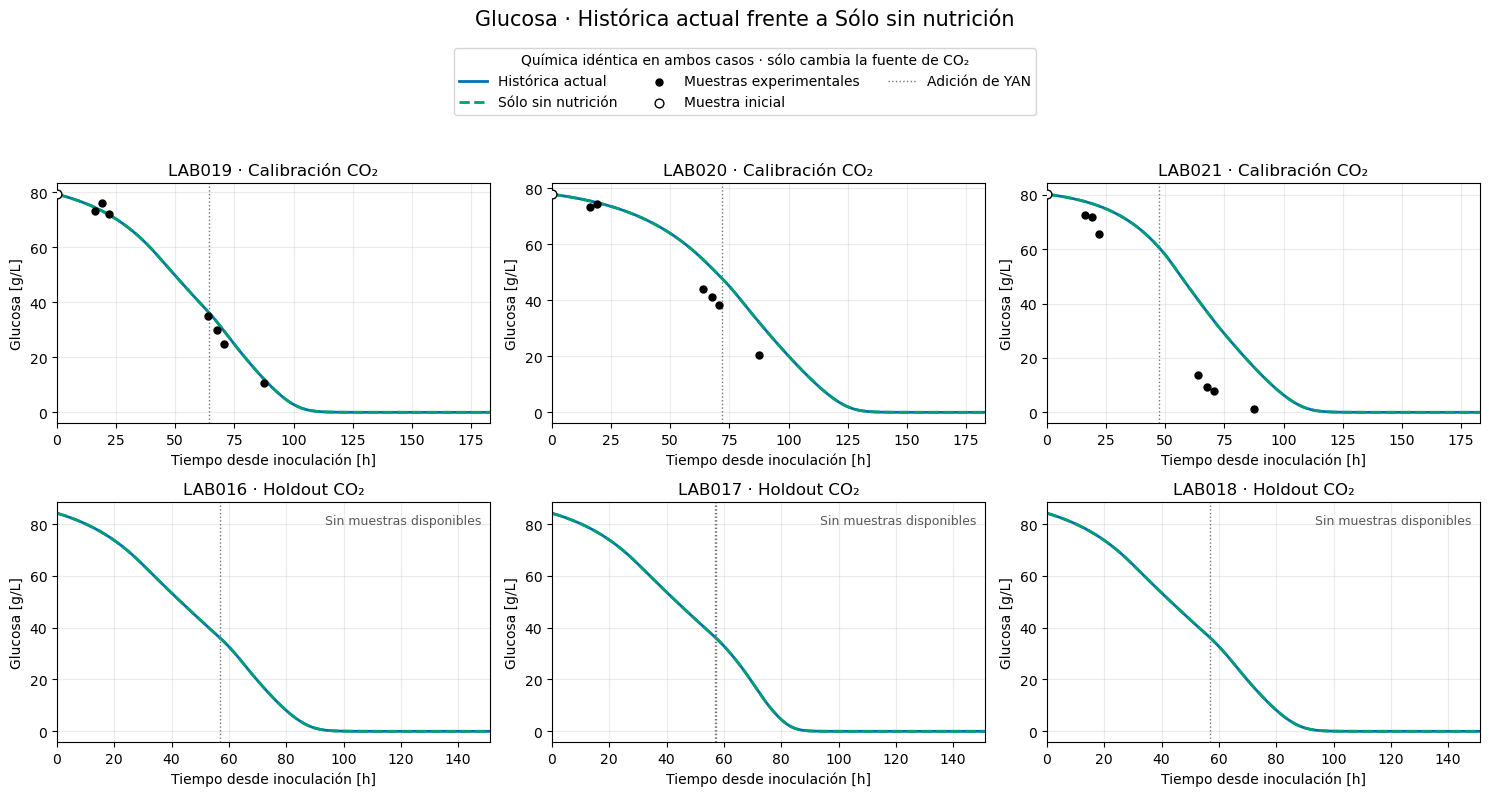

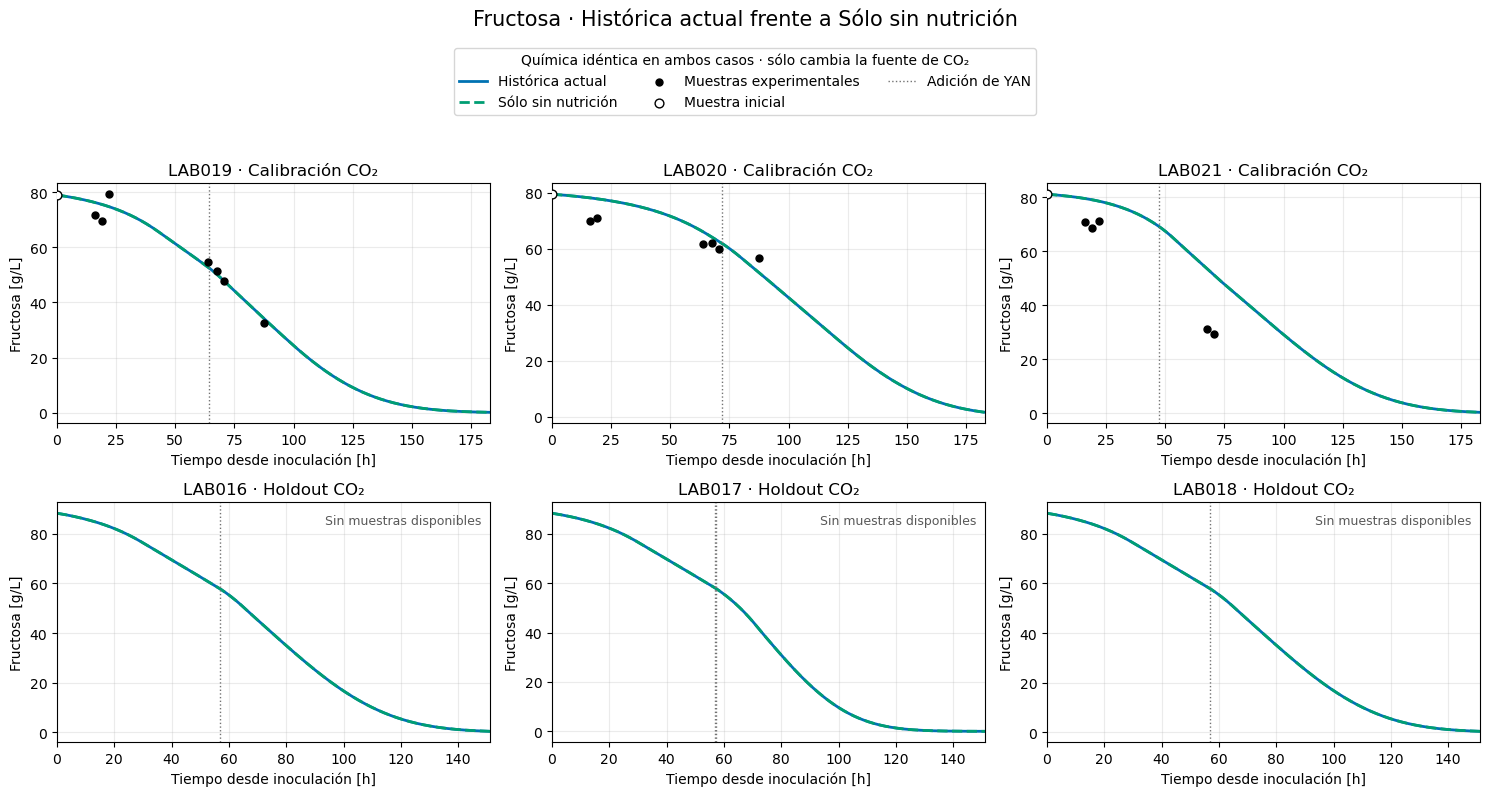

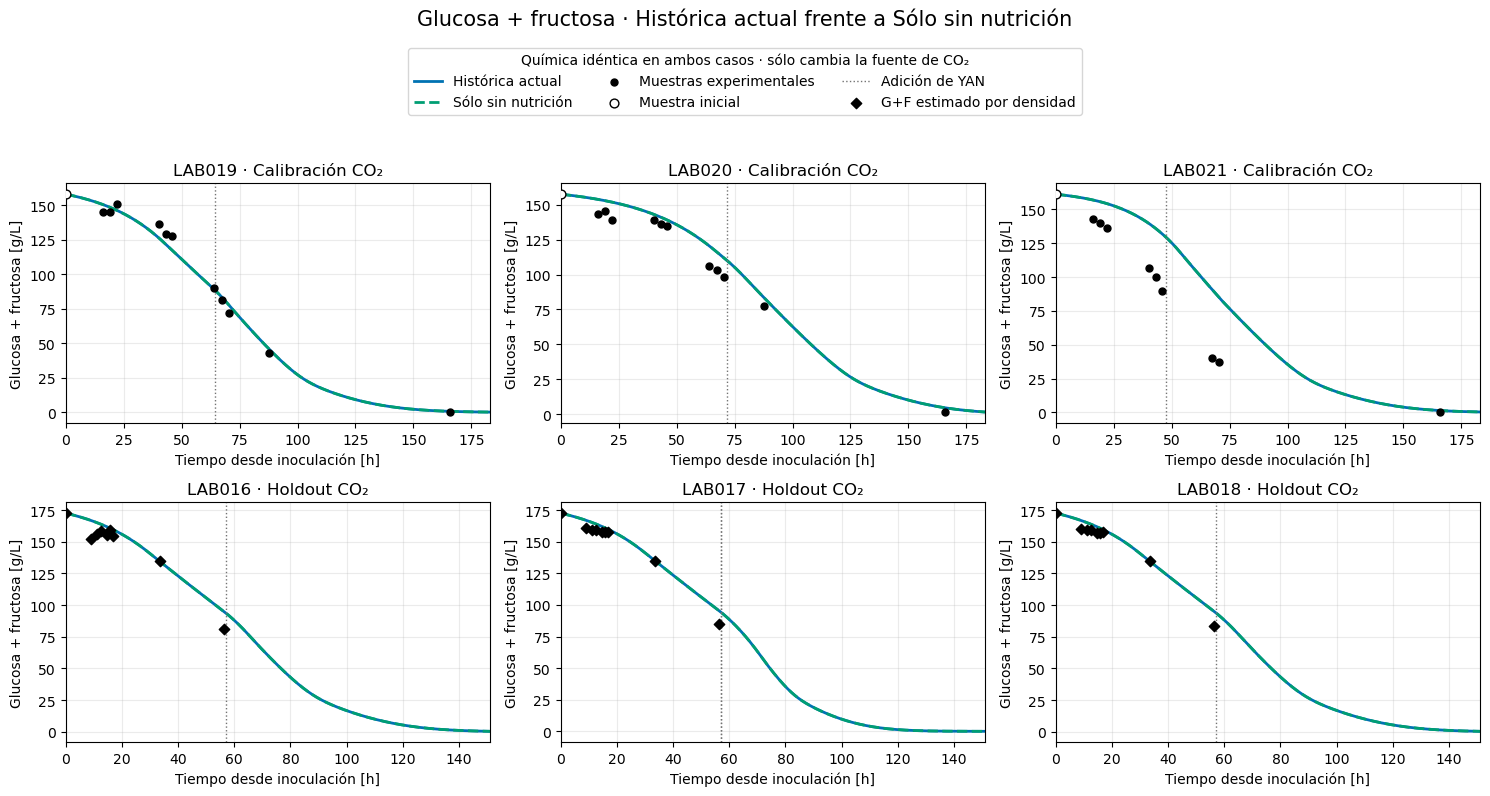

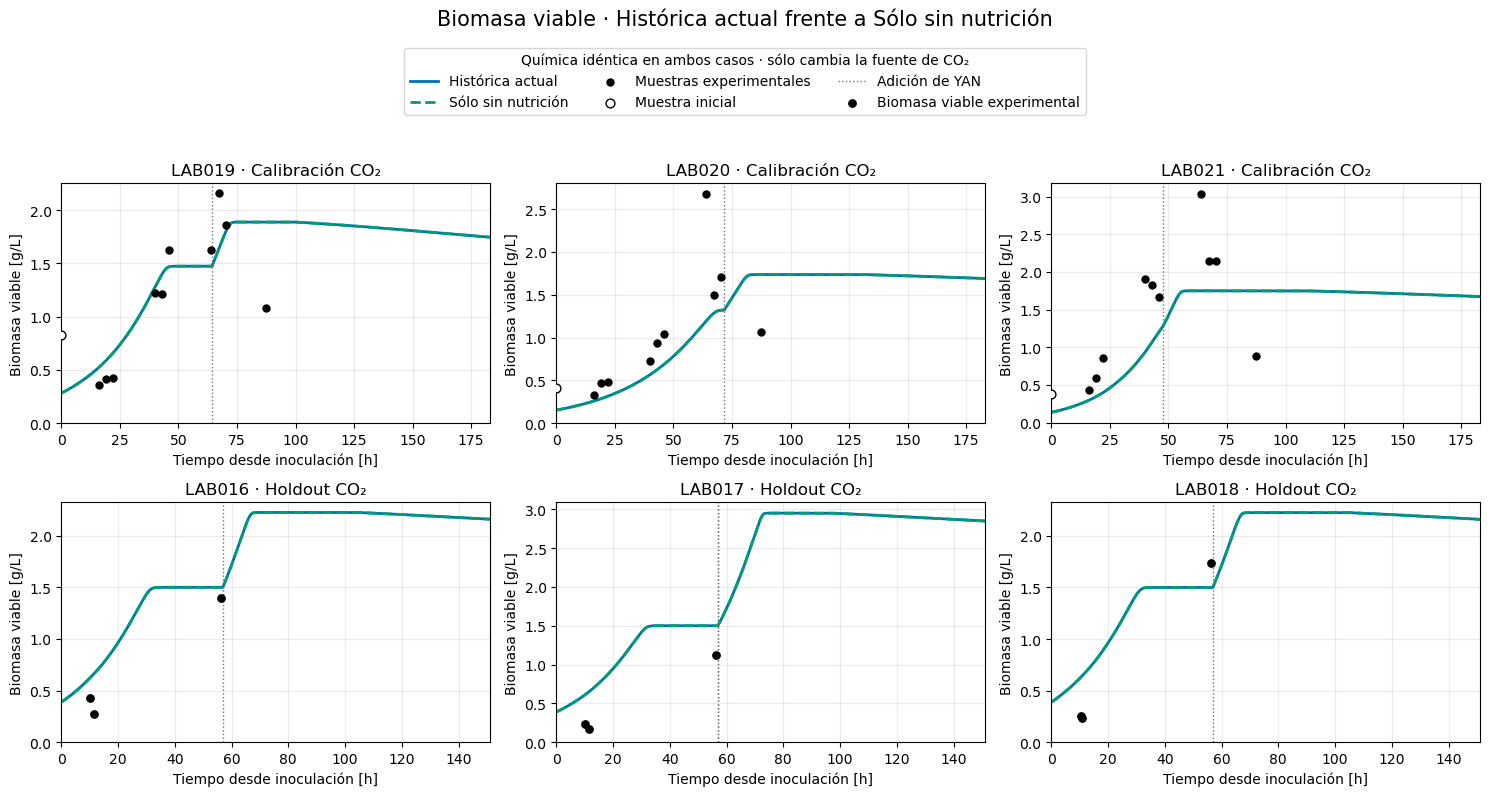

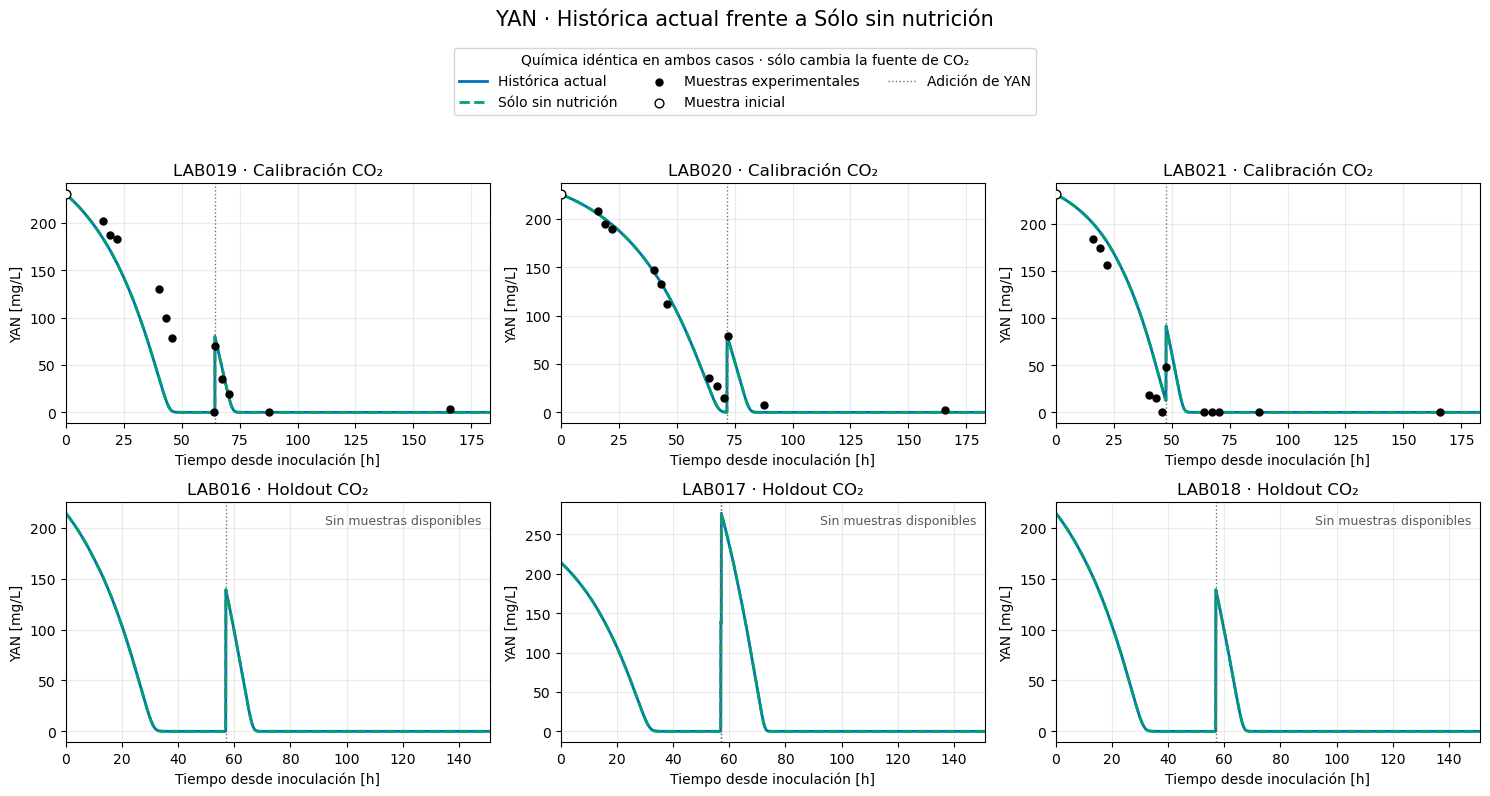

,LAB,variable,n_muestras,origen,ultimo_t_h
0,LAB019,Etanol,6,Química offline (incluye NUT numéricas),166.000000
1,LAB020,Etanol,6,Química offline (incluye NUT numéricas),166.000000
2,LAB021,Etanol,6,Química offline (incluye NUT numéricas),166.000000
3,LAB016,Etanol,0,Sin medición disponible,NaN
4,LAB017,Etanol,0,Sin medición disponible,NaN
5,LAB018,Etanol,0,Sin medición disponible,NaN
6,LAB019,Glucosa,8,Química offline (incluye NUT numéricas),87.500000
7,LAB020,Glucosa,7,Química offline (incluye NUT numéricas),87.500000
8,LAB021,Glucosa,8,Química offline (incluye NUT numéricas),87.500000
9,LAB016,Glucosa,0,Sin medición disponible,NaN


In [4]:
from dataclasses import replace
chemical_pairs={};chemical_rows=[]
chemical_variables=[('E','Etanol',1.,'g/L'),('G','Glucosa',1.,'g/L'),('F','Fructosa',1.,'g/L'),('GF','Glucosa + fructosa',1.,'g/L'),('X','Biomasa viable',1.,'g/L'),('N','YAN',1000.,'mg/L')]
chemical_theta_before=v.thetas['theta_nv2'].copy()
for lab in LABS:
 c=v.cache['theta_nv2',lab];batch=v.batches[lab]
 yes=c['core'].copy(deep=True)
 no=yes.copy(deep=True)  # The q0 gas-source alternative keeps the same chemical prediction.
 no['GF']=no.G+no.F
 assert np.allclose(yes.iloc[0][['X','N','G','F','E']],no.iloc[0][['X','N','G','F','E']])
 assert np.array_equal(no[['X','N','G','F','E']].to_numpy(),yes[['X','N','G','F','E']].to_numpy())
 chemical_pairs[lab]=(yes,no)
 for key,title,scale,unit in chemical_variables:
  delta=(yes[key]-no[key]).to_numpy()*scale
  chemical_rows.append(dict(LAB=lab,variable=title,unidad=unit,max_diferencia_absoluta=float(abs(delta).max()),hora_max_diferencia=float(c['time'][abs(delta).argmax()]),diferencia_final=float(delta[-1]),final_historica=float(yes[key].iloc[-1]*scale),final_solo_sin_nutricion=float(no[key].iloc[-1]*scale),fin_h=float(c['time'][-1])))
assert max(row['max_diferencia_absoluta'] for row in chemical_rows)==0.
display(pd.DataFrame(chemical_rows).round(5))
observation_counts=[]
for key,title,scale,unit in chemical_variables:
 fig,axes=plt.subplots(2,3,figsize=(15,8))
 for ax,lab in zip(axes.flat,LABS):
  yes,no=chemical_pairs[lab]
  ax.plot(yes.index,yes[key]*scale,color='#0072B2',lw=2,label='Histórica actual')
  ax.plot(no.index,no[key]*scale,color='#009E73',ls='--',lw=2,label='Sólo sin nutrición')
  # Keep every numeric measurement for each variable, including initial and NUT rows.
  from wine_fermentation.comparison import chemical_observations,CHEMICAL_COLUMNS
  if lab in LABS[:3]:
   pts=chemical_observations(v.chem,lab,key)
   col=CHEMICAL_COLUMNS[key]
   initial=pts.loc[pts.t_h.eq(0)]
   later=pts.loc[~pts.t_h.eq(0)]
   ax.scatter(later.t_h,later[col]*scale,s=25,color='black',zorder=5,label='Muestras experimentales')
   if len(initial):ax.scatter(initial.t_h,initial[col]*scale,s=40,facecolors='white',edgecolors='black',zorder=6,label='Muestra inicial')
   observation_counts.append(dict(LAB=lab,variable=title,n_muestras=len(pts),origen='Química offline (incluye NUT numéricas)',ultimo_t_h=float(pts.t_h.max()) if len(pts) else np.nan))
  elif key=='GF':
   pts=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']).copy()
   values=2.5*(pts.density_g_l-1000.)
   assert np.allclose(values,pts.GF_density_g_l,equal_nan=True)
   ax.scatter(pts.t_h,values,s=28,marker='D',color='black',zorder=5,label='G+F estimado por densidad')
   observation_counts.append(dict(LAB=lab,variable=title,n_muestras=len(pts),origen='2.5*(densidad_g_L-1000)',ultimo_t_h=float(pts.t_h.max())))
  elif key=='X':
   pts=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l'])
   ax.scatter(pts.t_h,pts.X_viable_g_l,s=28,color='black',zorder=5,label='Biomasa viable experimental')
   observation_counts.append(dict(LAB=lab,variable=title,n_muestras=len(pts),origen='Conteo y viabilidad; conversión existente a g/L',ultimo_t_h=float(pts.t_h.max())))
  else:
   ax.text(.98,.95,'Sin muestras disponibles',ha='right',va='top',transform=ax.transAxes,fontsize=9,color='.35')
   observation_counts.append(dict(LAB=lab,variable=title,n_muestras=0,origen='Sin medición disponible',ultimo_t_h=np.nan))
  for j,(event,dose) in enumerate(v.cache['theta_nv2',lab]['events']):
   ax.axvline(event,color='.45',ls=':',lw=1,label='Adición de YAN' if j==0 else None)
  ax.set_title(lab+(' · Calibración CO₂' if lab in LABS[:3] else ' · Holdout CO₂'))
  ax.set_xlabel('Tiempo desde inoculación [h]');ax.set_ylabel(f'{title} [{unit}]')
  ax.grid(alpha=.25);ax.set_xlim(yes.index[0],yes.index[-1]);ax.set_ylim(bottom=min(0.,ax.get_ylim()[0]))
 legend_items={}
 for ax in axes.flat:
  hs,ls=ax.get_legend_handles_labels()
  for h,label in zip(hs,ls):legend_items.setdefault(label,h)
 labels=list(legend_items);handles=list(legend_items.values())
 fig.suptitle(f'{title} · Histórica actual frente a Sólo sin nutrición',fontsize=15,y=.99)
 fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.95),ncol=3,title='Química idéntica en ambos casos · sólo cambia la fuente de CO₂')
 fig.tight_layout(rect=(0,0,1,.86));plt.show()
assert chemical_theta_before==v.thetas['theta_nv2']
assert before==hashes()

display(pd.DataFrame(observation_counts))
assert len(observation_counts)==36
